# Radio-Frequency-Tagged Fluorescence Imaging: One Detector, Many Pixels

Companion to [`dgs/fire_imaging.py`](../dgs/fire_imaging.py).

**Scope, stated up front.** The idea comes from FIRE (Fluorescence Imaging
using Radiofrequency-tagged Emission; Diebold, Buckley, Gossett and Jalali,
*Nature Photonics* 2013). This notebook does **not** model that instrument's
optics and does not reproduce its numbers. It models the signal-processing
idea, which is the one FM radio uses: give every channel its own frequency,
send them all down one wire, and separate them with a Fourier transform.

| Step | What happens | Class it belongs to |
|---|---|---|
| Tag | each pixel's excitation light beats at its own radio frequency | physics (interference) |
| Emit | the fluorophore re-emits, low-pass filtered by its lifetime | modern physics, circuits (RC filter) |
| Detect | one detector sums all pixels and counts photons | statistics (Poisson) |
| Sample | an ADC digitises the sum | digital logic (Nyquist) |
| Demodulate | multiply by a reference and accumulate | digital logic (lock-in / FFT) |

Brightness is measured in **detected photons per ADC sample** throughout.

In [1]:
import sys, pathlib, math
sys.path.insert(0, str(pathlib.Path.cwd().parent))

import numpy as np
import sympy as sp
import matplotlib.pyplot as plt

from dgs.fire_imaging import (
    tag_frequencies, throughput, design_line, lifetime_response, lifetime_from_phase,
    simulate_line, demodulate_line, tone_amplitudes, measure_phase_lag,
    predicted_sigma, predicted_snr, simulate_image,
)
SEED = 0
print("using dgs.fire_imaging directly (not reimplemented)")

using dgs.fire_imaging directly (not reimplemented)


# Part 1 — Where the radio frequency comes from

Overlap two laser beams whose optical frequencies differ by $\Delta\omega$.
A detector responds to intensity $|E_1+E_2|^2$. SymPy does the algebra:

In [2]:
t, w, dw, E1, E2 = sp.symbols("t omega Delta_omega E1 E2", positive=True)
field = E1*sp.exp(sp.I*w*t) + E2*sp.exp(sp.I*(w + dw)*t)
intensity = sp.simplify(sp.expand(field*sp.conjugate(field)).rewrite(sp.cos))
print("I(t) =", intensity)
print("depends on the optical frequency omega?", intensity.has(w))

I(t) = E1**2 + 2*E1*E2*cos(Delta_omega*t) + E2**2
depends on the optical frequency omega? False


The optical frequency (hundreds of THz, far too fast for any detector)
has dropped out. What is left is a constant plus a cosine at the
**difference** frequency, which can be a convenient radio frequency. With
equal beams the modulation depth is $2E_1E_2/(E_1^2+E_2^2)=1$.

Give each pixel in a row a different $\Delta\omega$ and every pixel has its
own "station".

# Part 2 — One line: a mess in time, a comb in frequency

Sixteen pixels tagged from 20 to 35 MHz. The detector output looks like
noise even though there is none here. Its spectrum is sixteen clean lines
whose heights are the pixel brightnesses.

ADC: fs = 88 MHz, 88 samples in a 1.0 us line
max recovery error (noiseless): 8.1e-13 photons/sample


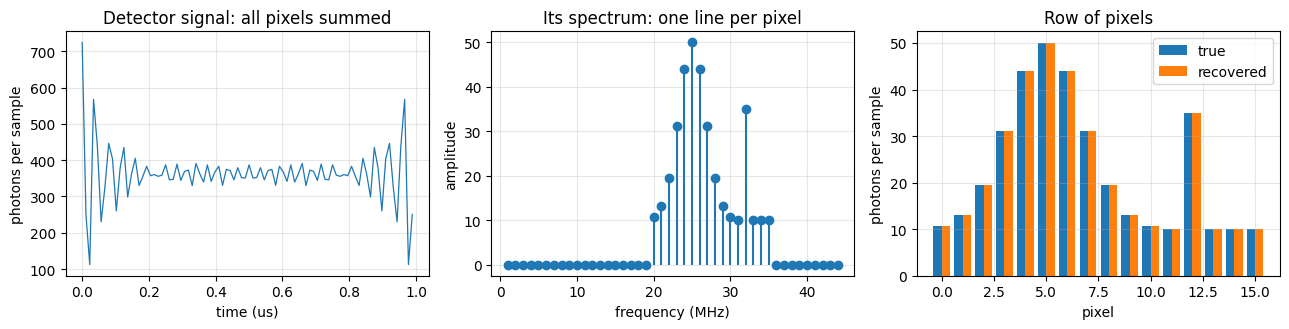

In [3]:
N, F0, DF = 16, 20e6, 1e6
d = design_line(N, F0, DF)
freqs, fs, n = d["freqs_hz"], d["fs_hz"], d["n_samples"]
truth = 10 + 40 * np.exp(-((np.arange(N) - 5) / 2.5) ** 2) + 25 * (np.arange(N) == 12)

signal = simulate_line(truth, freqs, fs, n)             # noiseless
recovered = demodulate_line(signal, freqs, fs)
print(f"ADC: fs = {fs/1e6:.0f} MHz, {n} samples in a {d['line_time_s']*1e6:.1f} us line")
print(f"max recovery error (noiseless): {np.max(np.abs(recovered - truth)):.1e} photons/sample")

spectrum = 2 / n * np.abs(np.fft.rfft(signal))
f_axis = np.fft.rfftfreq(n, 1 / fs)
fig, axes = plt.subplots(1, 3, figsize=(13, 3.4))
axes[0].plot(np.arange(n) / fs * 1e6, signal, lw=0.9)
axes[0].set(xlabel="time (us)", ylabel="photons per sample", title="Detector signal: all pixels summed")
axes[1].stem(f_axis[1:] / 1e6, spectrum[1:], basefmt=" ")
axes[1].set(xlabel="frequency (MHz)", ylabel="amplitude", title="Its spectrum: one line per pixel")
axes[2].bar(np.arange(N) - 0.2, truth, 0.4, label="true")
axes[2].bar(np.arange(N) + 0.2, recovered, 0.4, label="recovered")
axes[2].set(xlabel="pixel", ylabel="photons per sample", title="Row of pixels"); axes[2].legend()
for ax in axes: ax.grid(alpha=0.3)
fig.tight_layout(); plt.show()

# Part 3 — The speed limit: line rate = tag spacing

Two cosines at $f$ and $f+\Delta f$ are orthogonal over a record of length
$T$ only if $T$ is a multiple of $1/\Delta f$. So the shortest line that
separates neighbouring pixels lasts $1/\Delta f$, and

$$\text{line rate}=\Delta f,\qquad
\text{pixel rate}=N\,\Delta f=\text{RF bandwidth used}.$$

One pixel per second per hertz: you buy speed with bandwidth. The experiment
lights **one** pixel and records for three different durations. Anything
recovered in the other fifteen pixels is crosstalk.

line time 1.00 x (1/spacing): worst crosstalk =  1.59e-13 photons/sample (4.0e-13 % of the lit pixel)
line time 0.63 x (1/spacing): worst crosstalk =  7.17e+00 photons/sample (1.8e+01 % of the lit pixel)
line time 0.25 x (1/spacing): worst crosstalk =  3.11e+01 photons/sample (7.8e+01 % of the lit pixel)


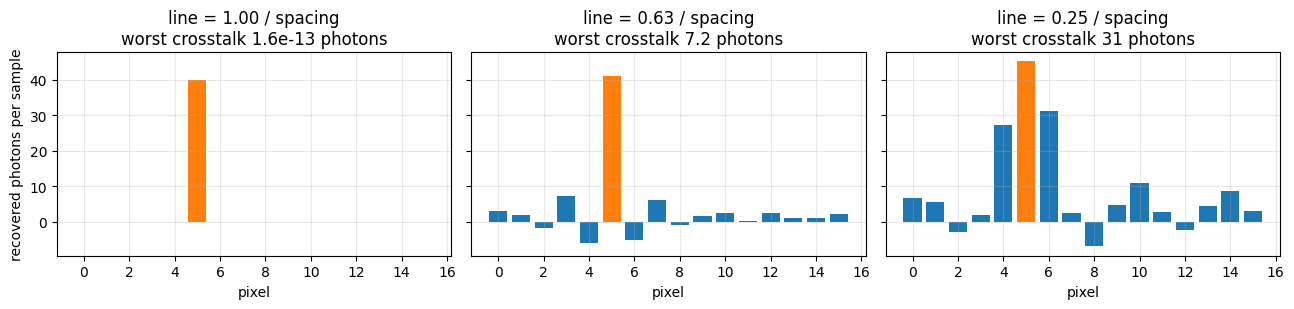


this design: line rate 1.0 MHz, pixel rate 16 Mpixel/s = RF bandwidth 16 MHz


In [4]:
one_hot = np.zeros(N); one_hot[5] = 40.0
fig, axes = plt.subplots(1, 3, figsize=(13, 3.2), sharey=True)
for ax, frac in zip(axes, (1.0, 0.63, 0.25)):
    n_cut = int(round(frac * n))
    rec = demodulate_line(simulate_line(one_hot, freqs, fs, n_cut), freqs, fs)
    leak = np.max(np.abs(np.delete(rec, 5)))
    ax.bar(np.arange(N), rec, color=["C1" if k == 5 else "C0" for k in range(N)])
    ax.set(xlabel="pixel", title=f"line = {frac:.2f} / spacing\nworst crosstalk {leak:.2g} photons")
    ax.grid(alpha=0.3)
    print(f"line time {frac:4.2f} x (1/spacing): worst crosstalk = {leak:9.2e} photons/sample "
          f"({100*leak/40:.1e} % of the lit pixel)")
axes[0].set_ylabel("recovered photons per sample")
fig.tight_layout(); plt.show()

tp = throughput(N, DF)
print(f"\nthis design: line rate {tp['line_rate_hz']/1e6:.1f} MHz, "
      f"pixel rate {tp['pixel_rate_hz']/1e6:.0f} Mpixel/s = RF bandwidth {tp['rf_bandwidth_hz']/1e6:.0f} MHz")

# Part 4 — Digital logic: Nyquist and the lock-in

**Nyquist.** The ADC must sample faster than twice the highest tag. Below
that, a tag shows up at the wrong frequency (it aliases) and lands on some
other pixel's station. The module refuses such a design. To see what the
refusal protects you from, the cell also aliases a tone by hand.

In [5]:
try:
    simulate_line(truth, freqs, 60e6, n)                # highest tag is 35 MHz > 30 MHz
except ValueError as err:
    print("refused ->", err)

# What aliasing does: a 35 MHz tone sampled at 60 MHz is indistinguishable from 25 MHz.
fs_bad = 60e6
tj = np.arange(120) / fs_bad
print("\n35 MHz and 25 MHz tones sampled at 60 MHz are identical:",
      np.allclose(np.cos(2*np.pi*35e6*tj), np.cos(2*np.pi*25e6*tj)))

refused -> every tag frequency must lie in (0, fs/2 = 3e+07 Hz); got up to 3.5e+07 Hz -- the ADC would alias it

35 MHz and 25 MHz tones sampled at 60 MHz are identical: True


**The lock-in is a multiply-accumulate.** To read pixel $k$: multiply
every sample by $e^{-i2\pi f_kt_j}$ and add them up. In hardware that is one
multiplier and one adder per pixel (a MAC unit on an FPGA). When the tags sit
on FFT bins, doing all pixels at once is exactly an FFT.

In [6]:
bins = np.rint(freqs * n / fs).astype(int)
lockin = tone_amplitudes(signal, freqs, fs)
via_fft = 2 / n * np.fft.fft(signal)[bins]
print("lock-in equals FFT bins:", np.allclose(lockin, via_fft))
print(f"work per line: lock-in {N} pixels x {n} samples = {N*n} multiply-adds; "
      f"FFT ~ n log2 n = {int(n*math.log2(n))}")

lock-in equals FFT bins: True
work per line: lock-in 16 pixels x 88 samples = 1408 multiply-adds; FFT ~ n log2 n = 568


# Part 5 — Modern physics: the fluorophore is an RC filter

An excited molecule does not emit instantly. It waits a random time with
mean $\tau$ (the fluorescence lifetime, typically a few nanoseconds). The
emission is the excitation convolved with $e^{-t/\tau}/\tau$, which is a
first-order low-pass filter, the same transfer function as an RC circuit with
$RC=\tau$:

$$M(f)=\frac{1}{\sqrt{1+(2\pi f\tau)^2}},\qquad \varphi(f)=\arctan(2\pi f\tau).$$

Two consequences. Tags far above $1/(2\pi\tau)$ are washed out, which caps
the usable bandwidth and therefore the pixel rate. And the phase lag
measures $\tau$.

Below: a wide comb, 10 to 167.5 MHz, on a dye with $\tau=4$ ns (an
illustrative value in the range of common dyes).

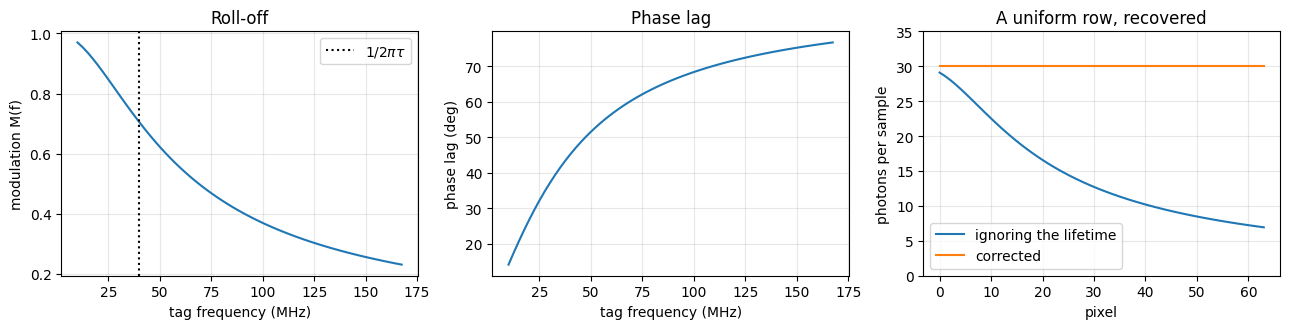

corner frequency 1/(2 pi tau) = 39.8 MHz
uncorrected: last pixel reads 6.9 instead of 30.0 (false 77 % shading across the row)
corrected  : max error 5.2e-11


In [7]:
TAU = 4e-9
NW, F0W, DFW = 64, 10e6, 2.5e6
dw_ = design_line(NW, F0W, DFW)
fw, fsw, nw = dw_["freqs_hz"], dw_["fs_hz"], dw_["n_samples"]
flat = np.full(NW, 30.0)                                # a uniformly bright row

M, lag = lifetime_response(fw, TAU)
sig = simulate_line(flat, fw, fsw, nw, tau_s=TAU)
uncorrected = demodulate_line(sig, fw, fsw, tau_s=0.0, method="magnitude")
corrected = demodulate_line(sig, fw, fsw, tau_s=TAU)

fig, axes = plt.subplots(1, 3, figsize=(13, 3.4))
axes[0].plot(fw / 1e6, M); axes[0].axvline(1 / (2*np.pi*TAU) / 1e6, color="k", ls=":", label=r"$1/2\pi\tau$")
axes[0].set(xlabel="tag frequency (MHz)", ylabel="modulation M(f)", title="Roll-off"); axes[0].legend()
axes[1].plot(fw / 1e6, np.degrees(lag))
axes[1].set(xlabel="tag frequency (MHz)", ylabel="phase lag (deg)", title="Phase lag")
axes[2].plot(uncorrected, label="ignoring the lifetime"); axes[2].plot(corrected, label="corrected")
axes[2].set(xlabel="pixel", ylabel="photons per sample", title="A uniform row, recovered", ylim=(0, 35)); axes[2].legend()
for ax in axes: ax.grid(alpha=0.3)
fig.tight_layout(); plt.show()

print(f"corner frequency 1/(2 pi tau) = {1/(2*np.pi*TAU)/1e6:.1f} MHz")
print(f"uncorrected: last pixel reads {uncorrected[-1]:.1f} instead of 30.0 "
      f"(false {100*(1-uncorrected[-1]/30):.0f} % shading across the row)")
print(f"corrected  : max error {np.max(np.abs(corrected - flat)):.1e}")

### Precision measurement: lifetime from phase

Time is hard to measure at the nanosecond scale; phase at a known frequency
is easy. Each tag gives $\tau=\tan\varphi/(2\pi f)$. With photon noise, 300
repeated lines of a bright uniform row (3000 photons per sample per pixel)
show how well a single line pins down a 4 ns lifetime, and which tags do it
best.

Which tag *should* be best? Every tag has the same amplitude noise (Part 6),
so the phase noise grows as $1/M=\sqrt{1+x^2}$ with $x=2\pi f\tau$, and
propagating through $\tau=\tan\varphi/(2\pi f)$ gives
$$\sigma_\tau\;\propto\;\frac{(1+x^2)^{3/2}}{x},$$
which is smallest at $x=1/\sqrt2$: a tag at about 0.71 of the corner
frequency.

true lifetime               : 4.000 ns
one tag, best (30 MHz)     : 3.991 +/- 0.166 ns per line
all 64 tags, weighted       : 4.017 +/- 0.042 ns per line
best tag measured at 30.0 MHz; predicted optimum 0.707 x corner = 28.1 MHz


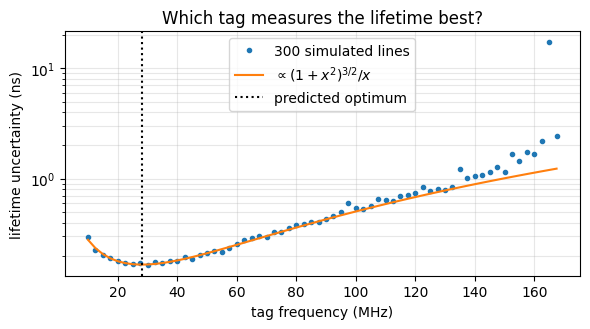

In [8]:
rng = np.random.default_rng(SEED)
# tan(phase)/(2 pi f) applied directly: lifetime_from_phase() rejects negative phases,
# but noise can push a small phase below zero and clipping it would bias the average.
bright = np.full(NW, 3000.0)
phases = np.array([measure_phase_lag(simulate_line(bright, fw, fsw, nw, tau_s=TAU, rng=rng), fw, fsw)
                   for _ in range(300)])                # shape (trials, pixels)
taus = np.tan(phases) / (2 * np.pi * fw)

per_tag_sigma = taus.std(axis=0)
weights = 1 / per_tag_sigma ** 2                        # inverse-variance weighting
combined = (taus * weights).sum(axis=1) / weights.sum()
best = np.argmin(per_tag_sigma)

print(f"true lifetime               : {TAU*1e9:.3f} ns")
print(f"one tag, best ({fw[best]/1e6:.0f} MHz)     : {taus[:, best].mean()*1e9:.3f} +/- {per_tag_sigma[best]*1e9:.3f} ns per line")
print(f"all 64 tags, weighted       : {combined.mean()*1e9:.3f} +/- {combined.std()*1e9:.3f} ns per line")
f_opt = 1 / (2 * np.pi * TAU) / np.sqrt(2)
print(f"best tag measured at {fw[best]/1e6:.1f} MHz; predicted optimum 0.707 x corner = {f_opt/1e6:.1f} MHz")

x = 2 * np.pi * fw * TAU
shape = (1 + x**2) ** 1.5 / x
shape *= per_tag_sigma.min() / shape.min()              # scale the predicted shape to the data

fig, ax = plt.subplots(figsize=(6, 3.4))
ax.semilogy(fw / 1e6, per_tag_sigma * 1e9, "o", ms=3, label="300 simulated lines")
ax.semilogy(fw / 1e6, shape * 1e9, "-", label=r"$\propto(1+x^2)^{3/2}/x$")
ax.axvline(f_opt / 1e6, color="k", ls=":", label="predicted optimum")
ax.set(xlabel="tag frequency (MHz)", ylabel="lifetime uncertainty (ns)",
       title="Which tag measures the lifetime best?")
ax.legend(); ax.grid(alpha=0.3, which="both"); fig.tight_layout(); plt.show()

Low tags barely lag (small phase, poor leverage); high tags lag a lot
but are washed out (little signal). The optimum sits between, a little below
the corner frequency. That is a general pattern in precision measurement: put
the probe where the response is steep *and* there is still signal. Combining
all 64 tags beats any single one.

# Part 6 — Statistics: shot noise and the multiplex penalty

Photon counts are Poisson: a mean of $N$ comes with fluctuations of
$\sqrt N$. Because **all** pixels land on one detector, the noise in every
pixel's estimate comes from **all** the light:

$$\sigma_k=\frac{\sqrt{2N_{\text{total}}}}{n\,m_k},\qquad
N_{\text{total}}=n\sum_j b_j ,$$

with $n$ samples per line and $m_k$ the modulation of pixel $k$. First check
the formula against 4000 simulated lines.

In [9]:
rng = np.random.default_rng(SEED)
trials = np.array([demodulate_line(simulate_line(truth, freqs, fs, n, rng=rng), freqs, fs)
                   for _ in range(4000)])
sigma = predicted_sigma(truth.sum(), n)
print(f"predicted sigma : {sigma:.3f} photons/sample (the same for every pixel)")
print(f"Monte Carlo     : {trials.std(axis=0).min():.3f} to {trials.std(axis=0).max():.3f} across the 16 pixels")
print(f"bias            : largest |mean - truth| = {np.max(np.abs(trials.mean(axis=0) - truth)):.3f} "
      f"(one standard error = {sigma/np.sqrt(4000):.3f}; the largest of 16 is expected near 2)")

predicted sigma : 2.869 photons/sample (the same for every pixel)
Monte Carlo     : 2.839 to 2.943 across the 16 pixels
bias            : largest |mean - truth| = 0.091 (one standard error = 0.045; the largest of 16 is expected near 2)


**The penalty.** A dim pixel (5 photons/sample) is measured twice: alone
in the dark, then beside fifteen bright neighbours (50 photons/sample each).
Its own signal is identical in both cases.

alone                  estimate =  5.01 +/- 0.34   SNR = 14.52   (predicted 14.83)


beside bright pixels   estimate =  4.93 +/- 4.19   SNR =  1.19   (predicted  1.21)

noise ratio 12.2x, predicted sqrt(N_total ratio) = 12.3x


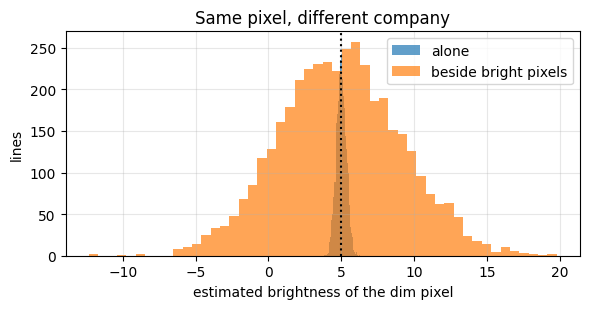

In [10]:
dim_alone = np.zeros(N); dim_alone[0] = 5.0
crowded = np.full(N, 50.0); crowded[0] = 5.0
rng = np.random.default_rng(SEED)
est = {}
for label, row in (("alone", dim_alone), ("beside bright pixels", crowded)):
    est[label] = np.array([demodulate_line(simulate_line(row, freqs, fs, n, rng=rng), freqs, fs)[0]
                           for _ in range(4000)])
    print(f"{label:<22} estimate = {est[label].mean():5.2f} +/- {est[label].std():.2f}   "
          f"SNR = {5.0/est[label].std():5.2f}   (predicted {predicted_snr(5.0, row.sum(), n):5.2f})")
print(f"\nnoise ratio {est['beside bright pixels'].std()/est['alone'].std():.1f}x, "
      f"predicted sqrt(N_total ratio) = {np.sqrt(crowded.sum()/dim_alone.sum()):.1f}x")

fig, ax = plt.subplots(figsize=(6, 3.2))
ax.hist(est["alone"], bins=50, alpha=0.7, label="alone")
ax.hist(est["beside bright pixels"], bins=50, alpha=0.7, label="beside bright pixels")
ax.axvline(5.0, color="k", ls=":")
ax.set(xlabel="estimated brightness of the dim pixel", ylabel="lines", title="Same pixel, different company")
ax.legend(); ax.grid(alpha=0.3); fig.tight_layout(); plt.show()

A camera, with one detector per pixel, does not pay this: each pixel
carries only its own shot noise. Frequency multiplexing trades that for
speed and a single fast detector. It suits bright, sparse scenes and hurts
when a faint feature sits next to a bright one. Negative estimates in the
histogram are honest: the estimator is linear and unbiased, so noise can push
a small value below zero.

# Part 7 — A whole image

A synthetic 48 x 64 scene (a bright blob, a thin filament, faint dots),
imaged row by row at three light levels with $\tau=4$ ns, lifetime
corrected. Tags run 20 to 83 MHz.

peak    2.0 photons/sample: correlation 0.527
peak   20.0 photons/sample: correlation 0.889


peak  200.0 photons/sample: correlation 0.987


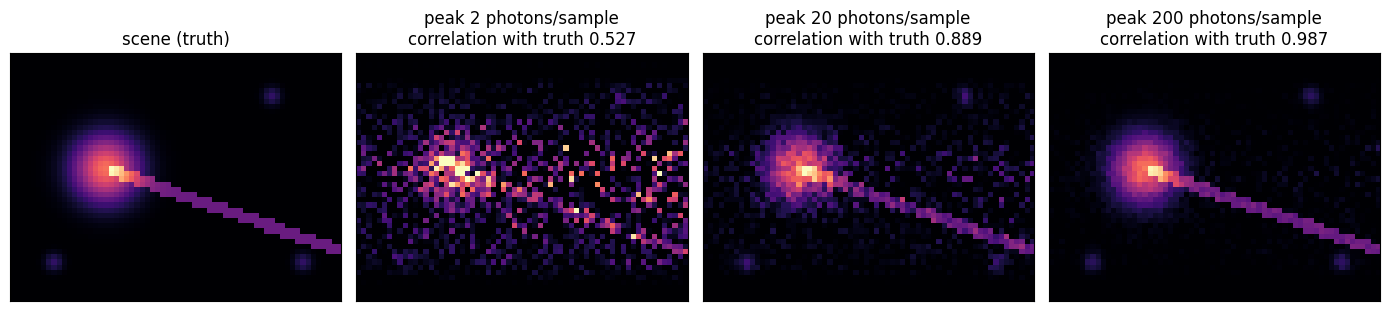


line time 1.0 us, frame time 48 us (20.8 k frames/s), ADC fs = 208 MHz, 208 samples per line
These rates are what the tag spacing allows. Whether enough photons arrive in that time is a separate question.


In [11]:
yy, xx = np.mgrid[0:48, 0:64]
scene = (np.exp(-((xx - 18)**2 + (yy - 22)**2) / 40.0)
         + 0.45 * (np.abs(yy - 22 - 0.35 * (xx - 18)) < 1.2) * (xx > 18)
         + 0.25 * sum(np.exp(-((xx - cx)**2 + (yy - cy)**2) / 3.0) for cx, cy in ((50, 8), (8, 40), (56, 40))))

fig, axes = plt.subplots(1, 4, figsize=(14, 3.3))
axes[0].imshow(scene, cmap="magma"); axes[0].set_title("scene (truth)")
for ax, peak in zip(axes[1:], (2.0, 20.0, 200.0)):
    rec, info = simulate_image(scene, 20e6, 1e6, peak_photons_per_sample=peak, tau_s=TAU, seed=SEED)
    r = np.corrcoef(rec.ravel(), info["truth"].ravel())[0, 1]
    ax.imshow(rec, cmap="magma", vmin=0, vmax=peak)
    ax.set_title(f"peak {peak:g} photons/sample\ncorrelation with truth {r:.3f}")
    print(f"peak {peak:6.1f} photons/sample: correlation {r:.3f}")
for ax in axes: ax.set_xticks([]); ax.set_yticks([])
fig.tight_layout(); plt.show()

print(f"\nline time {info['line_time_s']*1e6:.1f} us, frame time {info['frame_time_s']*1e6:.0f} us "
      f"({info['frame_rate_hz']/1e3:.1f} k frames/s), ADC fs = {info['fs_hz']/1e6:.0f} MHz, "
      f"{info['n_samples']} samples per line")
print("These rates are what the tag spacing allows. Whether enough photons arrive in that time is a separate question.")

# What this model leaves out

| Left out | Why it matters in a real instrument |
|---|---|
| How the frequency comb is made (acousto-optic deflector, interferometer) | sets the real pixel count, spot size and modulation depth |
| Detector and amplifier bandwidth, electronic noise, ADC bits | add noise and roll-off on top of the lifetime |
| Photobleaching and saturation of the dye | cap the photon rate; the photon levels here are illustrative |
| Multi-exponential lifetimes, scattering in tissue | the single-RC model is the simplest case |
| Scan mirror motion during a line | blurs the slow axis |
| Nonuniform excitation across the row | needs a flat-field calibration |

The results that do carry over are the three checked above: line rate equals
tag spacing, the lifetime caps useful tag frequency near $1/(2\pi\tau)$, and
every pixel inherits the shot noise of the whole row.

**Laser safety.** A real setup uses focused laser light and needs your
institution's laser safety training before any bench work. See
[`laser_safety.ipynb`](laser_safety.ipynb).

**Exercises**

1. Double the number of pixels at fixed spacing. What happens to the pixel
   rate, the required ADC rate, and each pixel's noise?
2. Record two beat periods per line (`periods=2`). Does the noise per pixel
   change the way $\sqrt{2N_{\text{total}}}/(n\,m)$ predicts?
3. Demodulate with `method="magnitude"` at the lowest light level. Why is the
   dark background no longer centred on zero?
4. A dye has $\tau=1$ ns. Up to what tag frequency is $M(f)>0.5$?